# Budget-Votes Correlation Check

This check wants to measure the correlation between budget and vote power, a strong positive correlation is expected.

In [3]:
# Add project source directory to import path.
import sys
import os
from pathlib import Path

parent_dir = str(os.path.join(Path.cwd().parent, 'src'))

if parent_dir not in sys.path:
    sys.path.insert(0, parent_dir)

# Imports.
import math
import numpy as np
import matplotlib.pyplot as plt
import fvopn_simulations as fvopn

In [4]:
size = 1000 # Number of nodes.
alpha = 5 # Root slots.
k = 20 # Multiplication factor.

rng = np.random.default_rng(42)

conf = fvopn.VoteAuctionModelV2Config(
    budgets=rng.beta(.5, 8, size),
    root_slots=alpha,
    multiplication_factor=k,
)

model = fvopn.VoteAuctionModelV2(conf, rng)

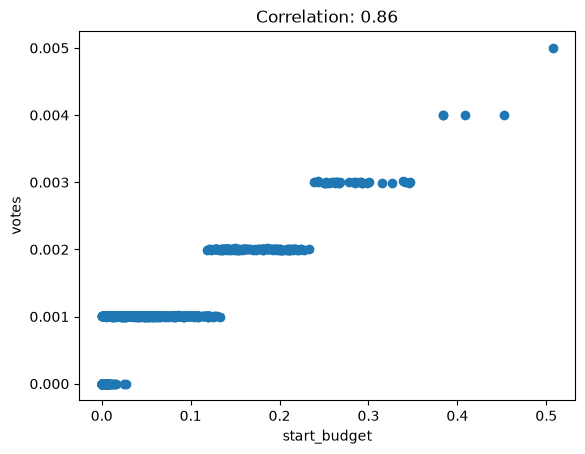

In [5]:
# Calculate correlation.

result = model.run()

corr = result['start_budget'].corr(result['votes'])

plt.scatter(result['start_budget'], result['votes'])
plt.xlabel('start_budget')
plt.ylabel('votes')
plt.title(f'Correlation: {corr:.2f}')

plt.show()